# 1. Question

All effects in this data were planted by us and declared before analysis (tag ground-truth-declared). This report says what the methods recovered, not what was discovered about real banks. Causal models use first attempts only (273,574), derived by a 30-minute rule with about 1.6 percent misclassification.

In [1]:
import os
import pandas as pd
from IPython.display import Image, display

rep_dir = os.path.abspath(os.path.join(os.getcwd(), "reports")) if os.path.exists("reports") else os.path.abspath(os.path.join(os.getcwd(), "..", "reports"))
qual_df = pd.read_csv(os.path.join(rep_dir, "phase4_scorecard_qualitative.csv"))
display(qual_df[["name", "expectation", "observed", "verdict"]])

,name,expectation,observed,verdict
0,Clearwave deploy window,coefficient strictly positive,"OR 19.7, 95% CI 16.8 to 23.1",HIT
1,Kestrel outage days flagged at bank level,all three outage days flagged,"z of 11.09, 11.69 and 8.06",HIT
2,Deploy window recovered by change-point,window within 2 days of 3 to 16 Aug,3 to 16 Aug exactly,HIT
3,Device equivalence (all-failures model),90% CIs inside 0.95 to 1.05,"Web 0.954 to 1.036, iOS 0.964 to 1.018",HIT
4,Device equivalence (four cause models),inside 0.95 to 1.05,No in all four (Web too wide),LOW POWER
5,Bank concentration,top 8 failure share 65 to 70 percent against v...,65.70 percent against 69.81 percent,HIT
6,"False positives among banks (within-tier, Holm)",0,0,HIT


# 2. Concentration is mostly volume

First-attempt failure rate is 9.05 percent. The top 8 banks hold 65.7 percent of failures on 69.8 percent of volume, so concentration mostly reflects volume. Small banks hold 8.25 percent of volume and 11.28 percent of failures.

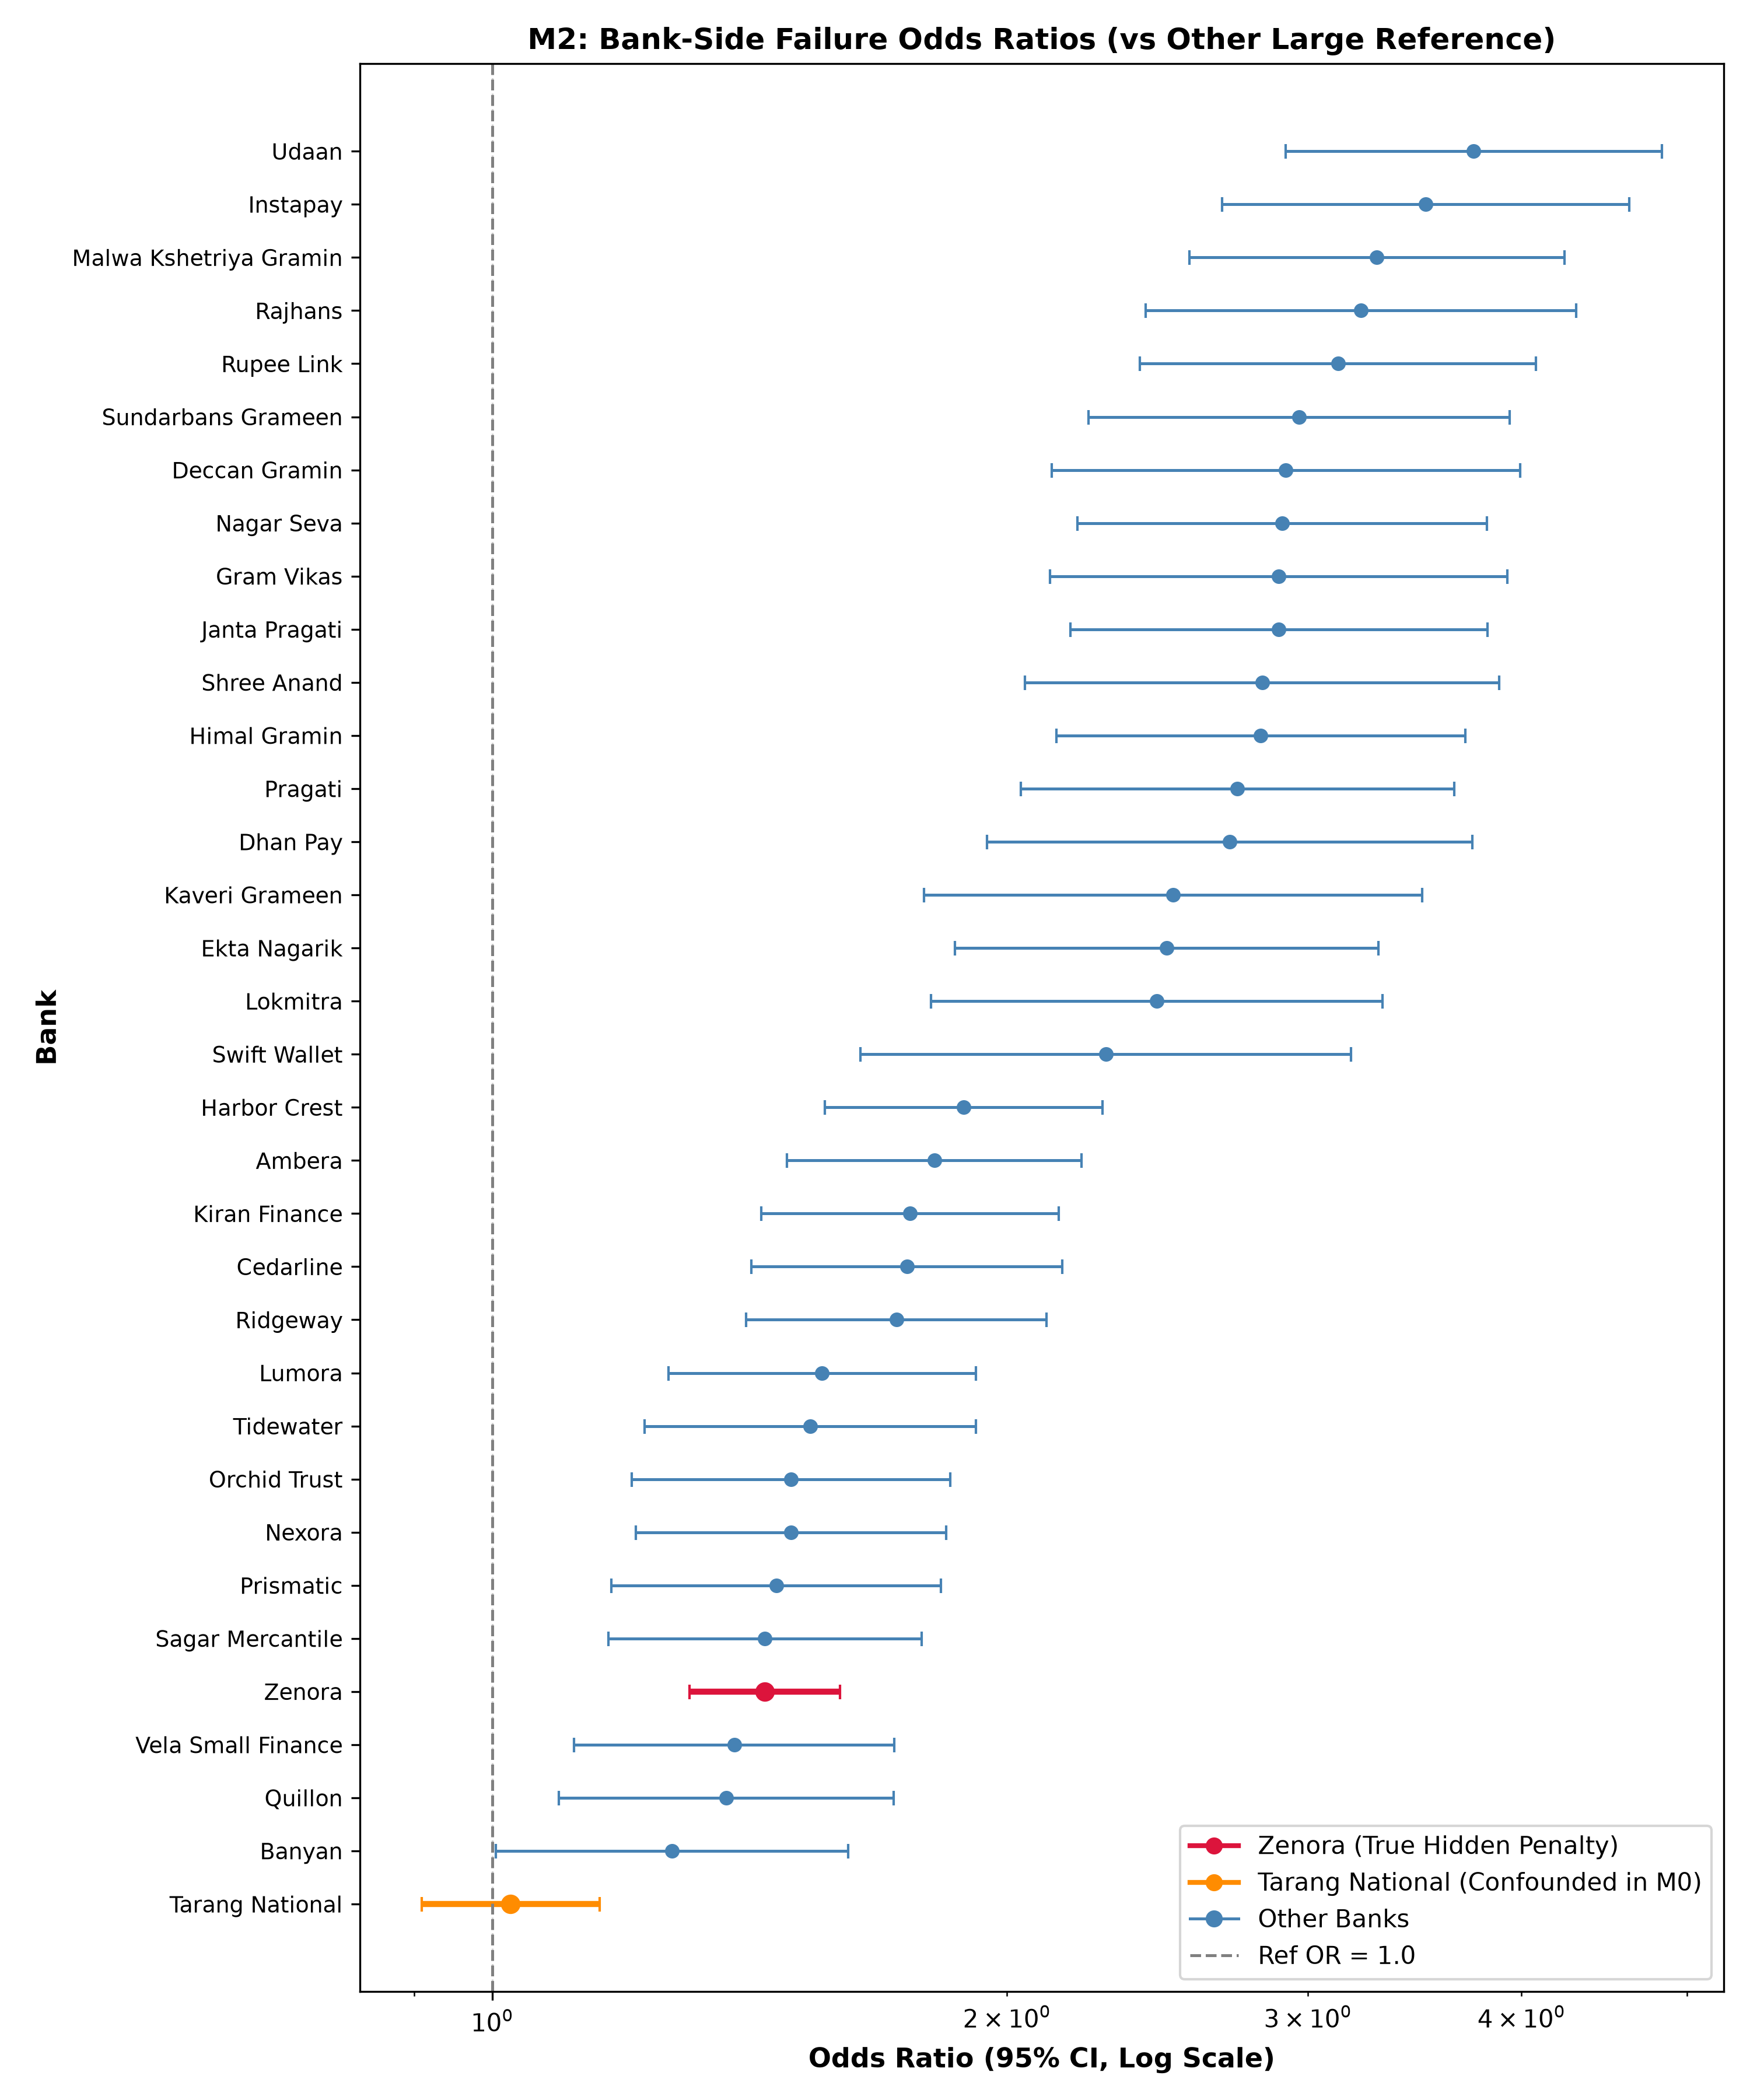

In [2]:
display(Image(filename=os.path.join(rep_dir, "figures", "p4d_bank_forest.png")))

# 3. The Simpson's trap

One bank has a real penalty: Zenora, odds ratio 1.44 (95 percent CI 1.30 to 1.60) on bank-side failures. Tarang National looks worse in raw data (odds ratio 1.07) only because 25.9 percent of its attempts are on 3G or 2G; with controls its odds ratio is 1.02. This is Simpson's paradox: the raw comparison pointed at the wrong bank.

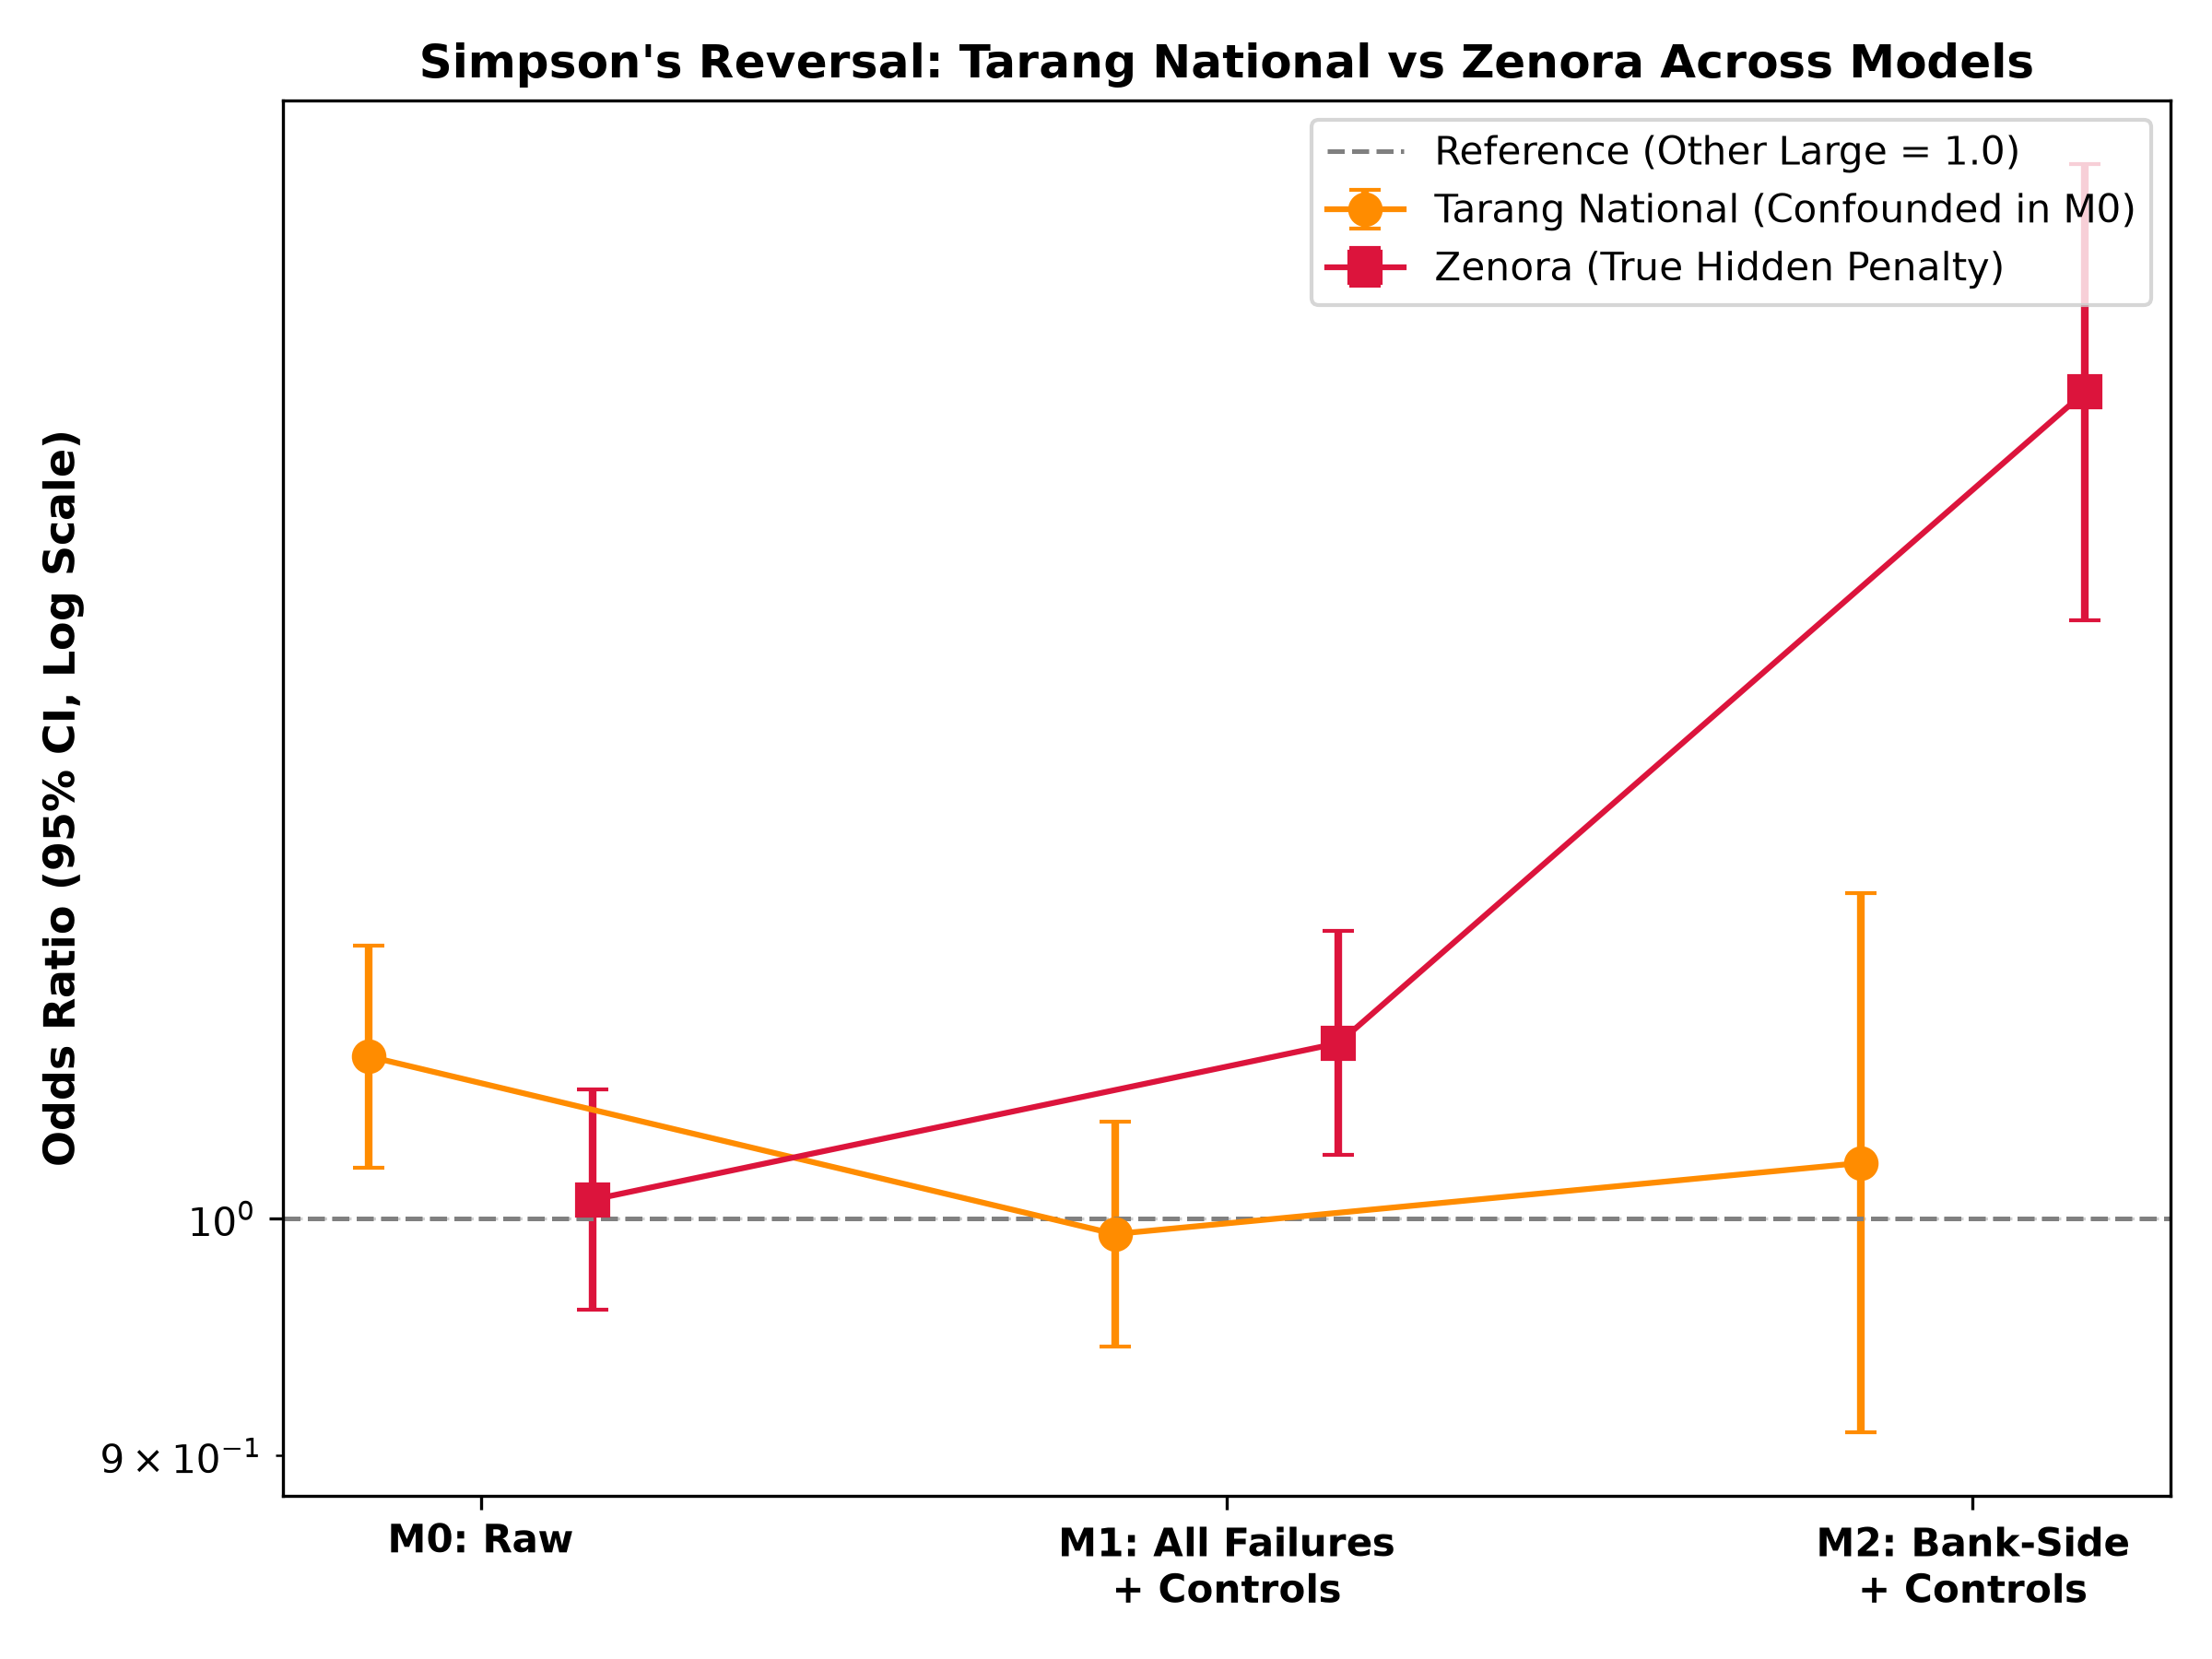

In [3]:
display(Image(filename=os.path.join(rep_dir, "figures", "p4d_raw_vs_adjusted.png")))

# 4. Device, network and PSP

3G and 2G raise network-failure odds about 3.5 and 4.9 times against WiFi. Peak hours (20:00 to 21:59) raise bank-side failure 2.1 times at Small banks, 1.25 times at Medium, about 1.1 times at Large. Clearwave had a PSP incident from 3 to 16 Aug (odds ratio 19.7), outside of which it is normal, while device type has no detectable effect.

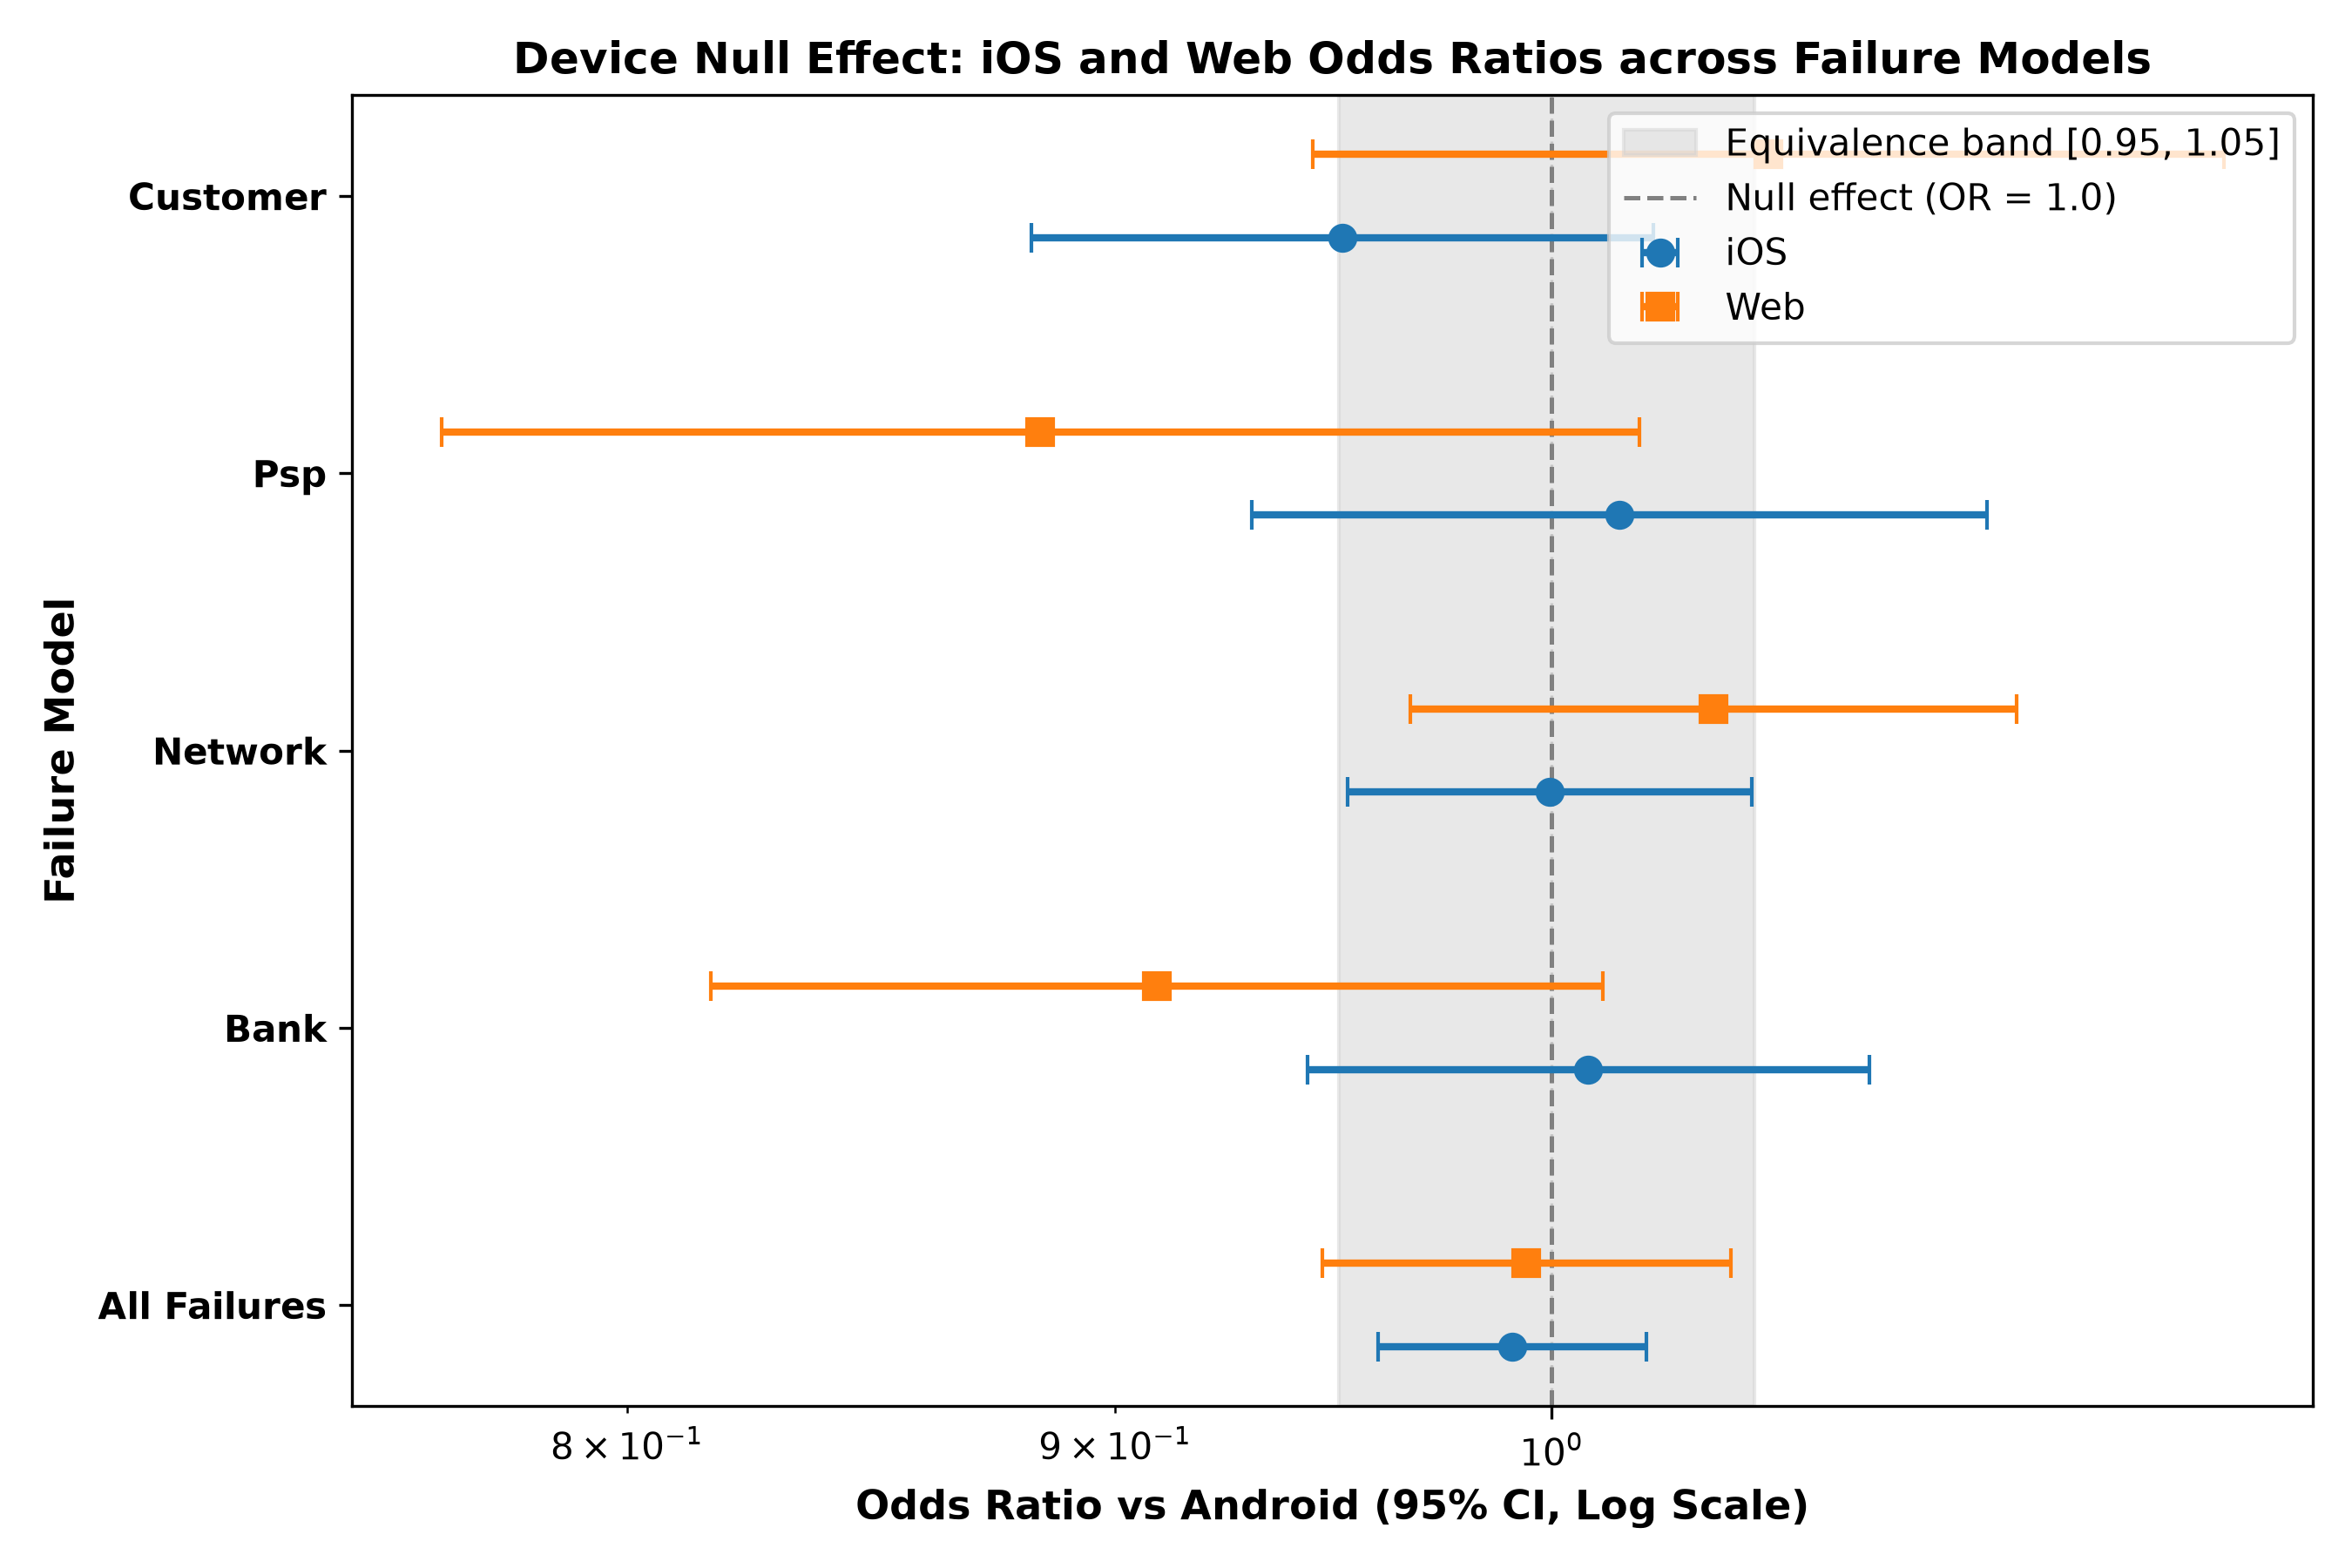

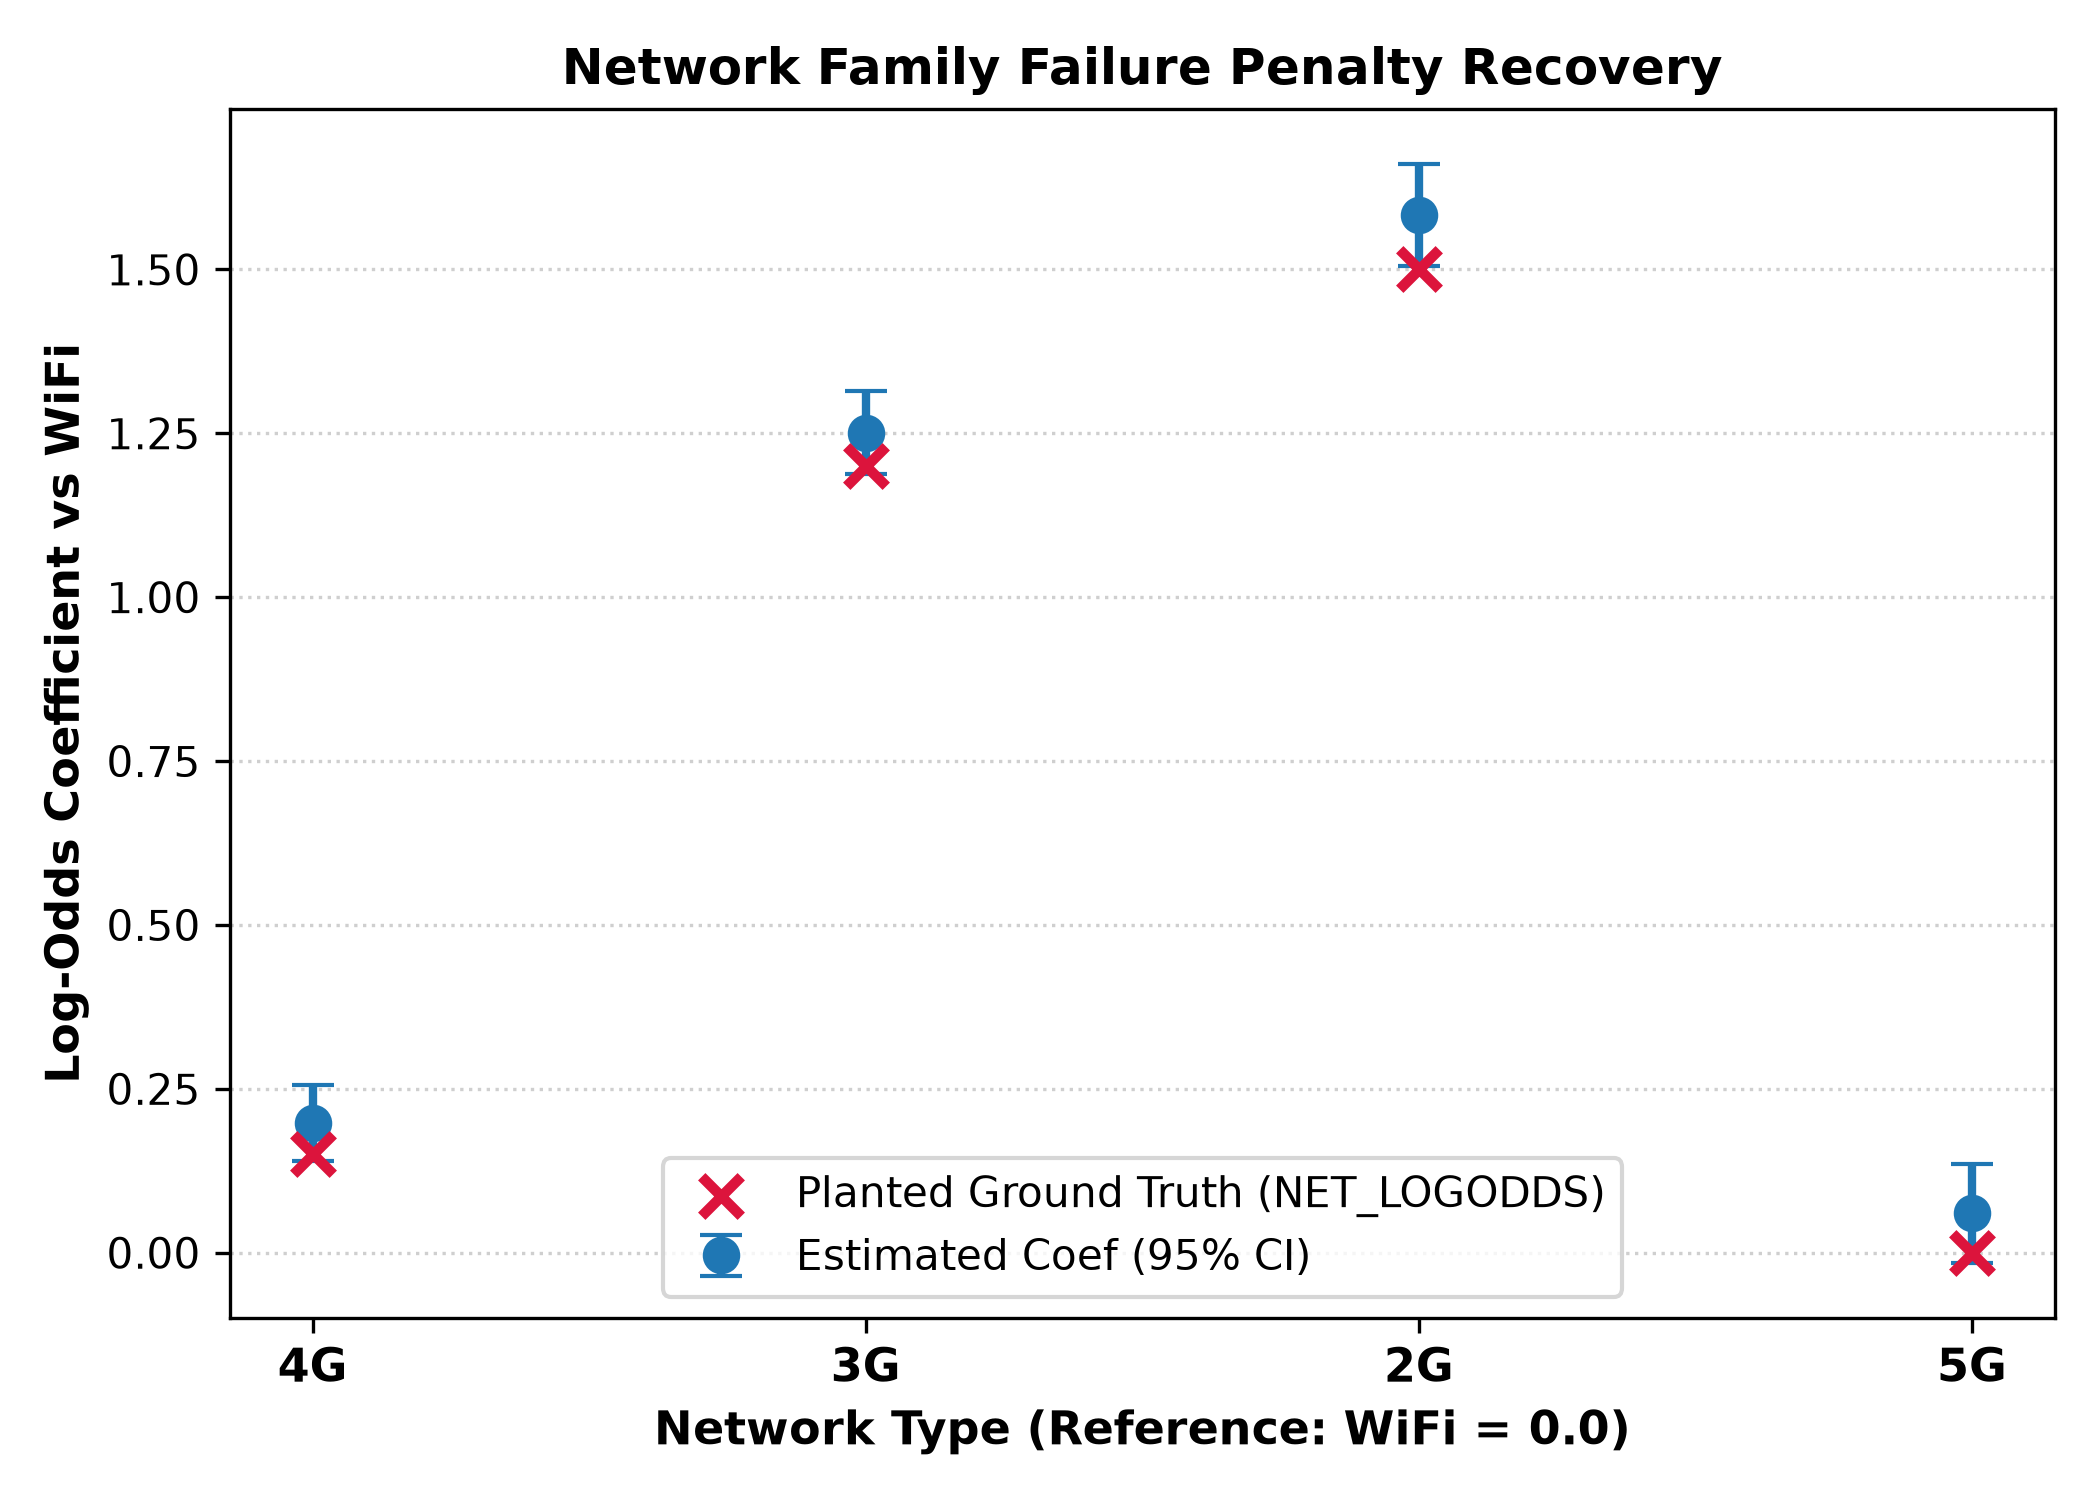

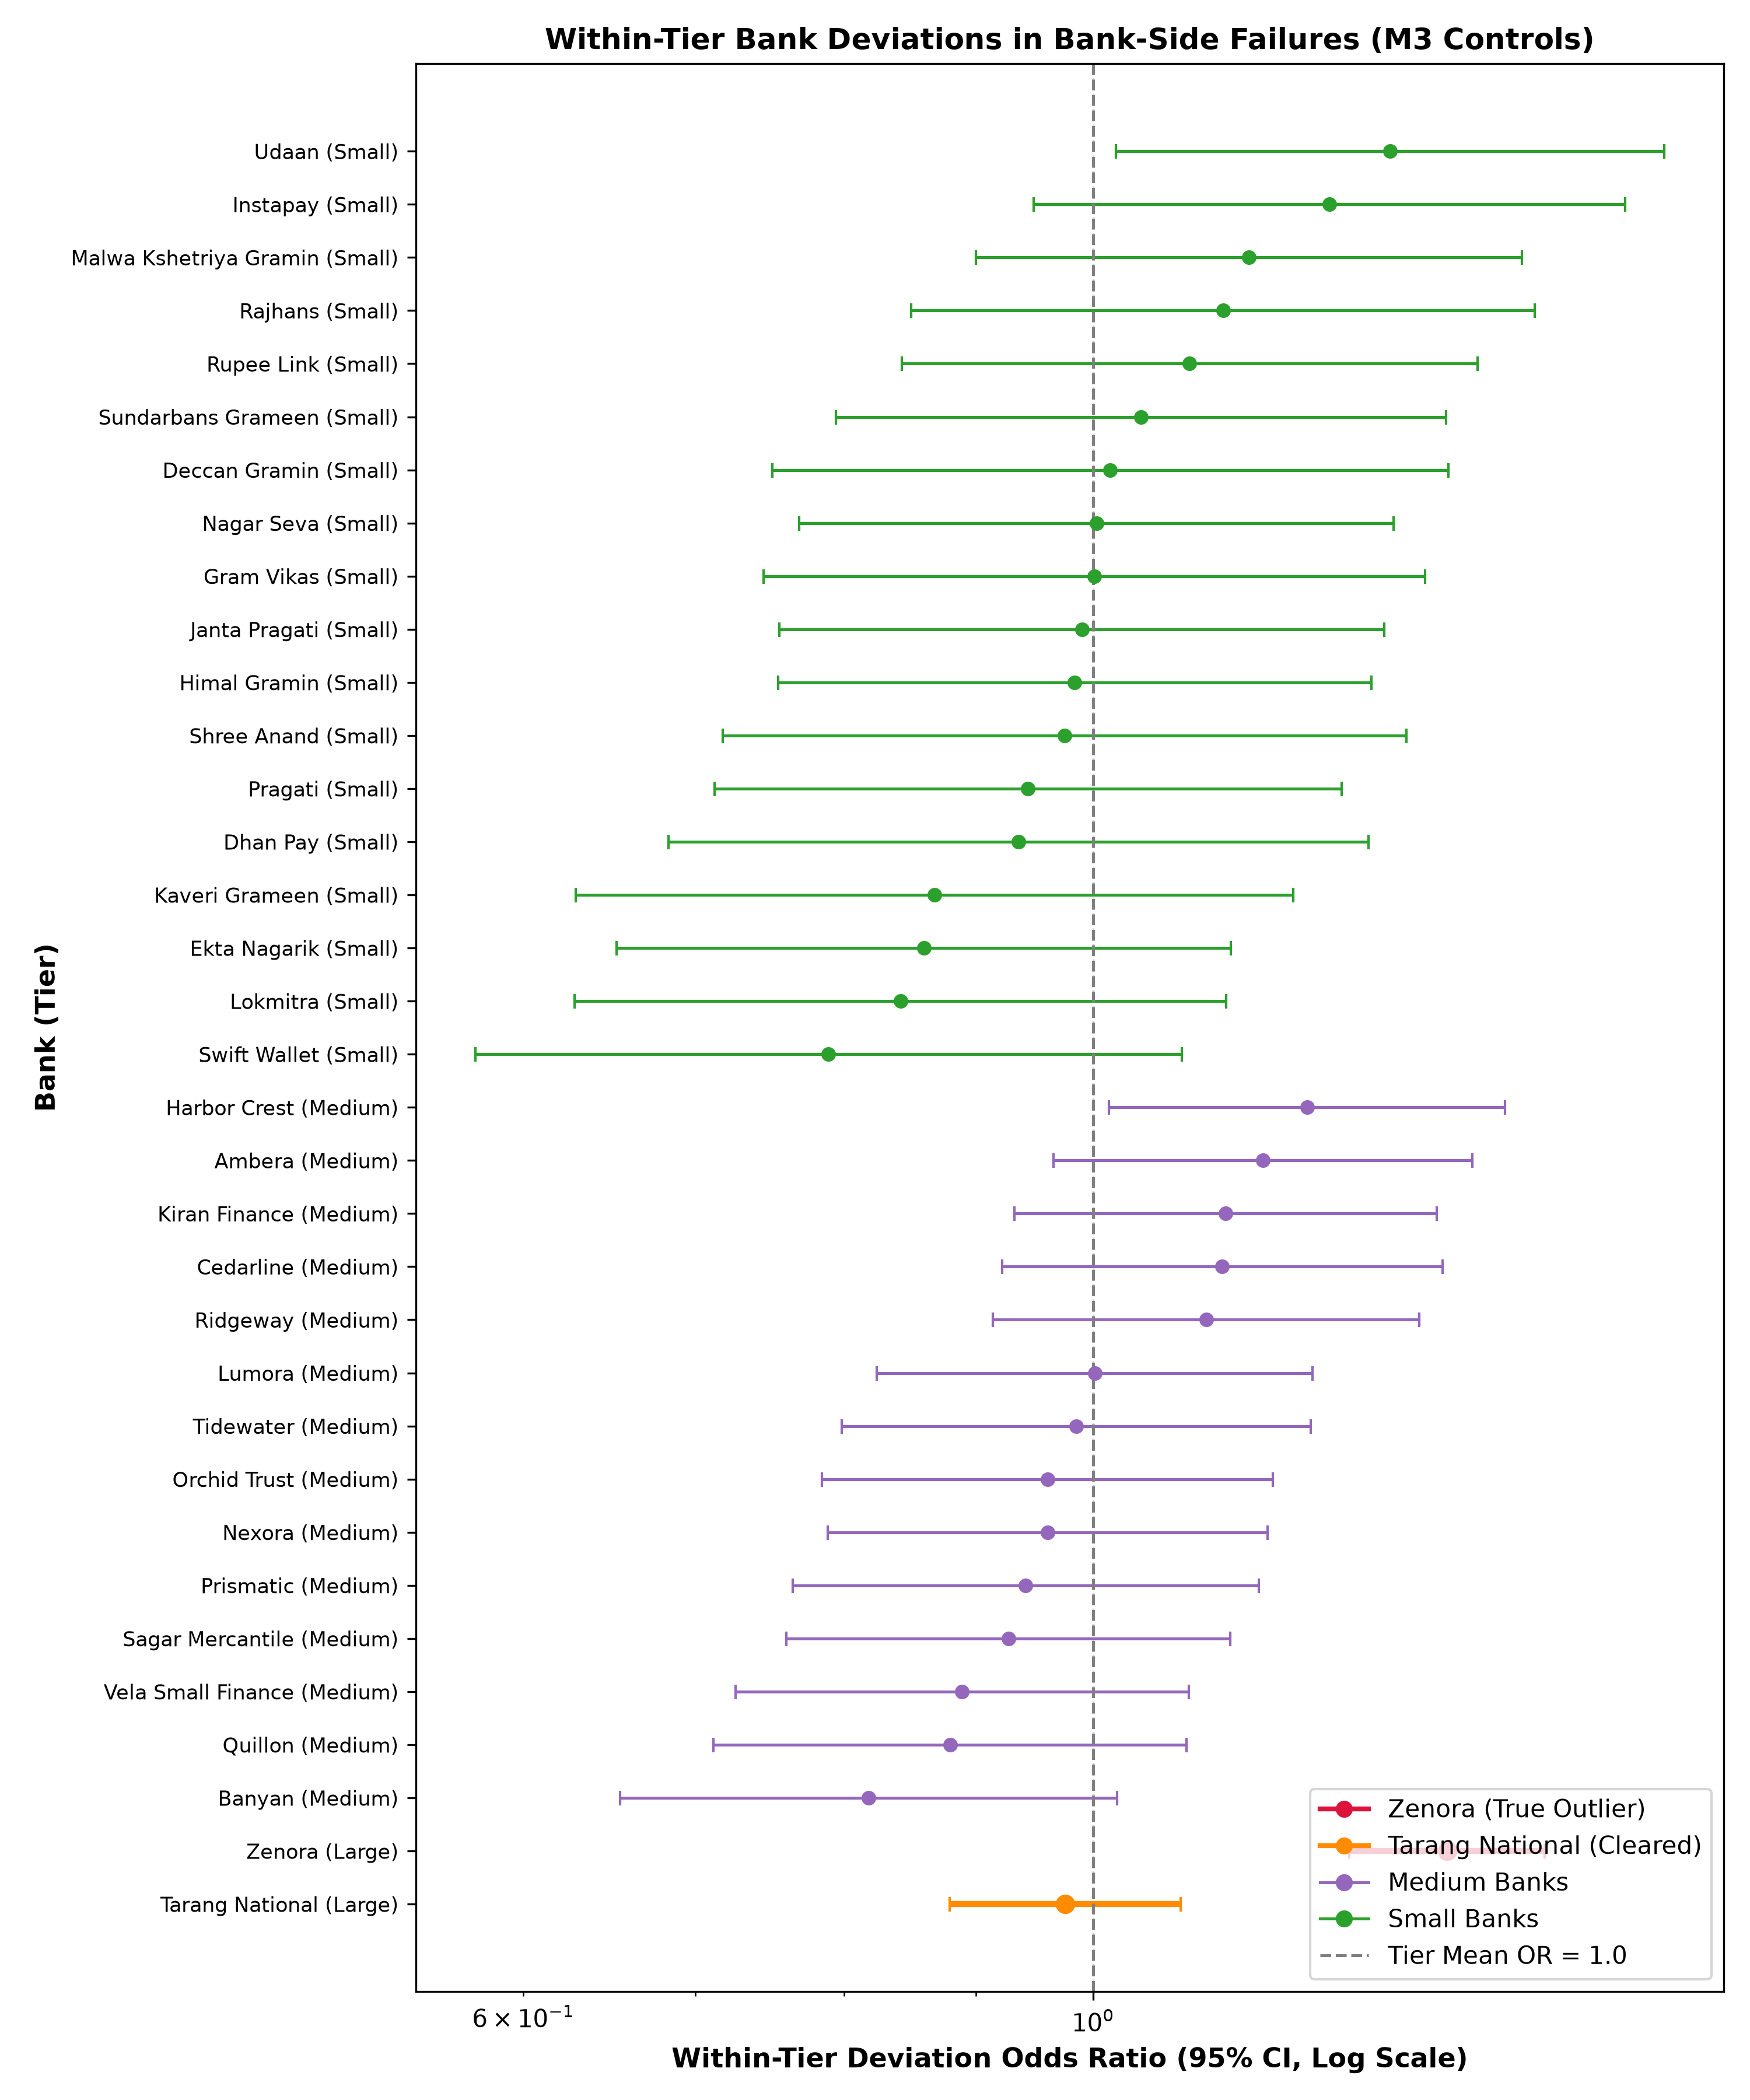

In [4]:
display(Image(filename=os.path.join(rep_dir, "figures", "p4e_device_forest.png")))
display(Image(filename=os.path.join(rep_dir, "figures", "p4e_network_recovery.png")))
display(Image(filename=os.path.join(rep_dir, "figures", "p4e_within_tier_banks.png")))

# 5. Scorecard against planted values

12 of 14 numeric estimates lie within 2 standard errors of the planted values. Outside: Peak Large (z 2.34) and 2G (z 2.10). Device equivalence could not be shown within individual cause models for Web due to low power.

,name,est,se,planted,z,verdict
0,Zenora bank-side (4D M2),0.366700,0.051684,0.35000,0.323119,HIT
1,Zenora vs tier average (4E),0.317400,0.044683,0.30625,0.249536,HIT
2,Tarang bank-side (4D M2),0.024500,0.061071,0.00000,0.401170,HIT
3,Peak Large,0.108600,0.046500,0.00000,2.335484,OUTSIDE 2 SE
4,Peak Medium,0.221600,0.067700,0.25000,-0.419498,HIT
5,Peak Small,0.761300,0.074800,0.80000,-0.517380,HIT
6,Network 4G,0.197800,0.029600,0.15000,1.614865,HIT
7,Network 3G,1.250600,0.032300,1.20000,1.566563,HIT
8,Network 2G,1.583300,0.039600,1.50000,2.103535,OUTSIDE 2 SE
9,Network 5G,0.060000,0.038300,0.00000,1.566580,HIT


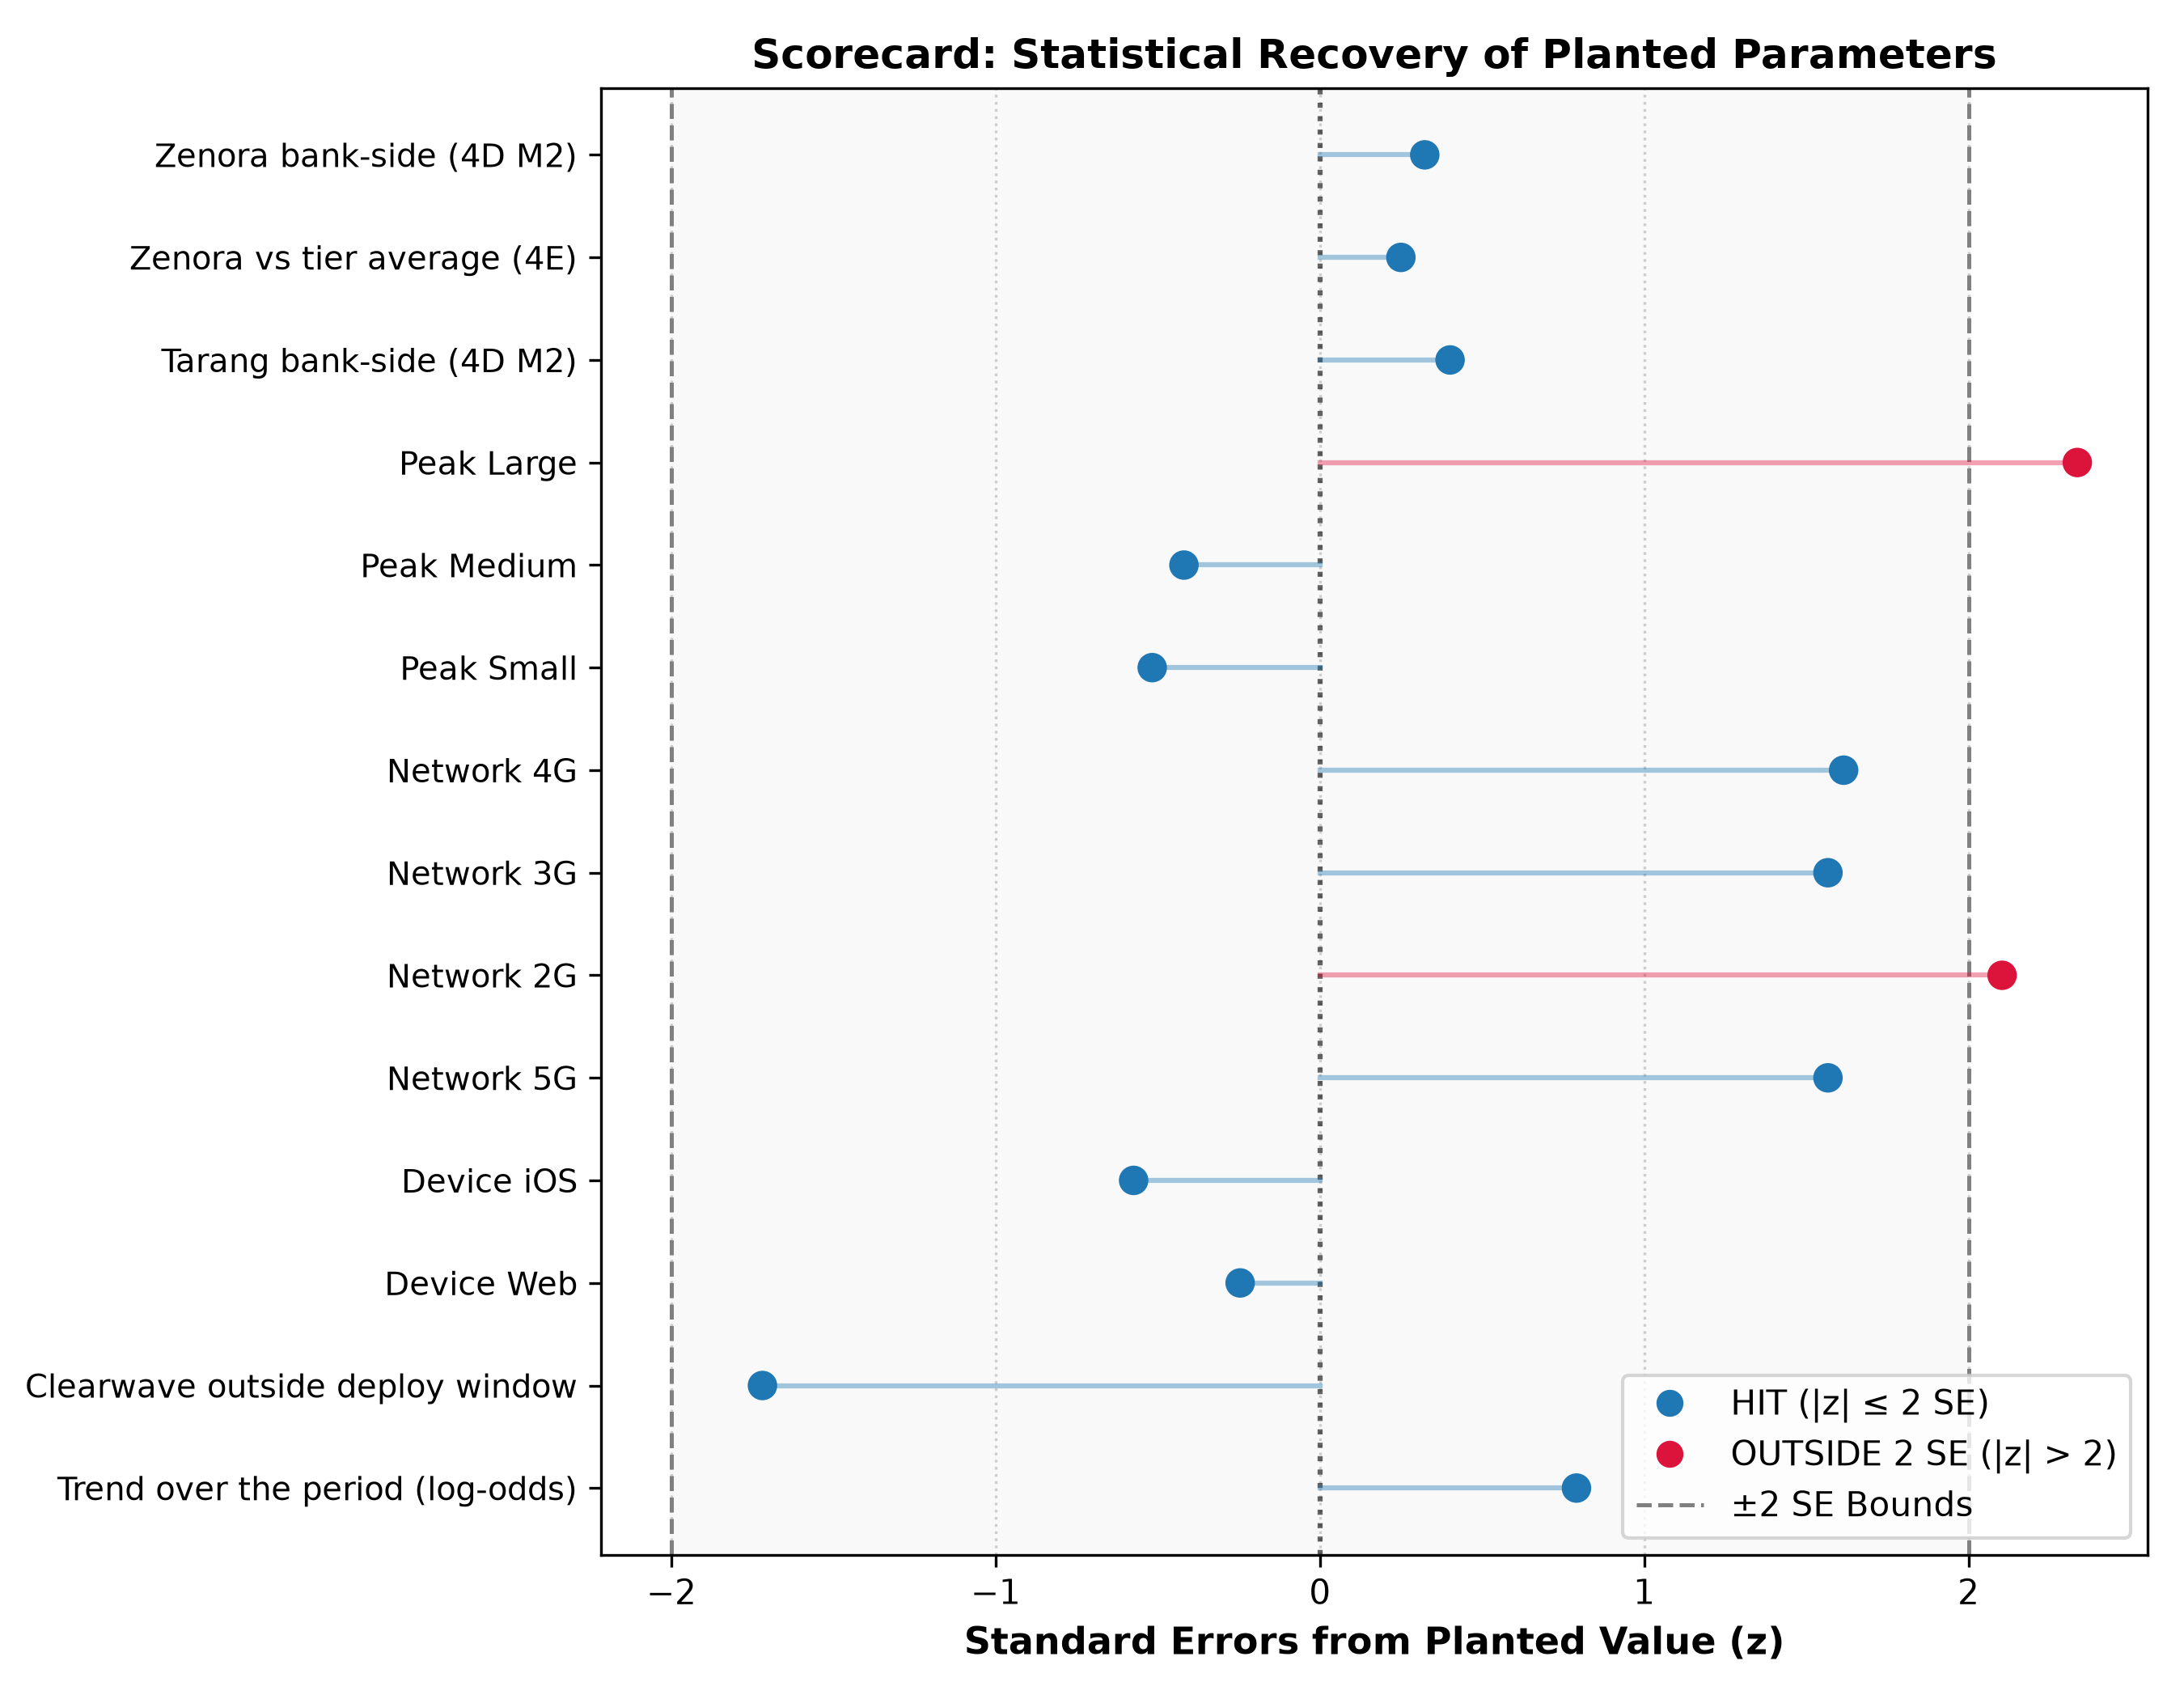

In [5]:
num_df = pd.read_csv(os.path.join(rep_dir, "phase4_scorecard.csv"))
display(num_df[["name", "est", "se", "planted", "z", "verdict"]])
display(Image(filename=os.path.join(rep_dir, "figures", "p4f_scorecard.png")))

# 6. Limits

This analysis is based on synthetic data with declared effects; real data would be messier. First attempts only were evaluated, retries are excluded from causal models, and 93 repaired UNK_01 rows were excluded from code-level work. The Large-bank peak estimate may be inflated by Kestrel's evening outage.

In [6]:
outside_2se = num_df[num_df["verdict"] == "OUTSIDE 2 SE"][["name", "est", "planted", "z", "verdict"]]
print("Estimates outside 2 standard errors (reported limitations):")
display(outside_2se)

Estimates outside 2 standard errors (reported limitations):


,name,est,planted,z,verdict
3,Peak Large,0.1086,0.0,2.335484,OUTSIDE 2 SE
8,Network 2G,1.5833,1.5,2.103535,OUTSIDE 2 SE
